# Lab 1 – First quantum circuits: entanglement and teleportation

**Goal.** In this lab, you will use `myQLM` to build and simulate quantum circuits. Starting from simple gates, you will prepare entangled states, investigate measurement statistics and correlations, and implement quantum teleportation. You will learn to distinguish an ideal statevector simulation from a finite-shot experiment, and to extract expectation values from measurement outcomes.

The emphasis is on using simulation to investigate quantum-mechanical predictions: **before running a circuit, make a prediction; then compare it with the numerical results.**

**Suggested duration:** approximately 3.5–4 hours. The timings below include time to discuss results and debug code; some questions are optional if you are short on time.

| Part | Content | Suggested time |
|---|---|---:|
| 0 | Setup and reminders on quantum circuits | 15 min |
| 1 | Bell states, measurements and correlations | 90 min |
| 2 | Quantum teleportation and verification | 90 min |
| 3 | Expectation values and observables | 35 min |
|   | Wrap-up | 10 min |



## Part 0: Setup and reminders on quantum circuits

In [ ]:
# only run if using Google Colab:
!pip install myqlm

Helper functions (those are given here to help you: read them, but do not modify them).

In [ ]:
import numpy as np

from qat.lang import QRoutine, H, CNOT, RY, RZ, Z, X, S, Program
from qat.qpus import get_default_qpu

qpu = get_default_qpu()

# ---- Running circuits and displaying results ------------------------------------------
def display_result(circuit, nbshots=0, idx=None):
    """Run a circuit and display its output.

    nbshots=0: ideal simulation; display basis states, probabilities and amplitudes.
    nbshots>0: finite-shot simulation; display the observed frequencies.
    idx: optional list of qubits to observe (all qubits if None).
    """
    result = qpu.submit(circuit.to_job(nbshots=nbshots, qubits=idx))
    if nbshots:
        print(f"Finite-shot simulation ({nbshots} shots):")
        for sample in result:
            print("State %s: frequency %s" % (sample.state, sample.probability))
    else:
        print("Ideal statevector simulation:")
        for sample in result:
            print("State %s: probability %s, amplitude %s" %
                  (sample.state, sample.probability, sample.amplitude))


## Basics on quantum circuits

The objective of this first part is to get familiar with building quantum circuits. We will use **myQLM**, a Python framework for constructing quantum programs and executing them on simulators. The documentation is available at https://myQLM.github.io.

A quantum circuit is represented by horizontal wires (qubits) evolving from left to right. Gates act on one or more qubits and represent unitary transformations. Measurements, introduced later, convert quantum information into classical outcomes.

<center><img src="img/circuit0.png"/></center>

### Unitary transformations

A unitary operator preserves the norm of a state and is reversible:

$$U^\dagger U = UU^\dagger = I.$$

An $n$-qubit pure state is represented by a vector with $2^n$ complex amplitudes. An operator acting on the full system is represented by a $2^n\times 2^n$ matrix.

### Standard quantum gates

**X gate – quantum NOT**

$$X=\begin{pmatrix}0&1\\1&0\end{pmatrix},$$

so $X|0\rangle=|1\rangle$ and $X|1\rangle=|0\rangle$.

*In myQLM: `X(q0)`.*

**H gate – superposition**

$$H=\frac{1}{\sqrt2}\begin{pmatrix}1&1\\1&-1\end{pmatrix}.$$

It maps $|0\rangle$ to $(|0\rangle+|1\rangle)/\sqrt2$ and $|1\rangle$ to $(|0\rangle-|1\rangle)/\sqrt2$. The minus sign is a **relative phase**: it does not change computational-basis probabilities immediately, but it can affect later interference.

*In myQLM: `H(q0)`.*

**CNOT – a controlled operation**

CNOT applies X to its target if its control is in state $|1\rangle$:

$$|00\rangle\mapsto|00\rangle,\quad |01\rangle\mapsto|01\rangle,\quad
|10\rangle\mapsto|11\rangle,\quad |11\rangle\mapsto|10\rangle.$$

*In myQLM: `CNOT(q0, q1)`.*

<center><img src="img/control_gates.png"/></center>

**Rotation gates**

The rotations used in this lab are

$$R_X(2\theta)=\begin{pmatrix}\cos\theta&-i\sin\theta\\-i\sin\theta&\cos\theta\end{pmatrix},\quad
R_Y(2\theta)=\begin{pmatrix}\cos\theta&-\sin\theta\\\sin\theta&\cos\theta\end{pmatrix},$$

$$R_Z(2\theta)=\begin{pmatrix}e^{-i\theta}&0\\0&e^{i\theta}\end{pmatrix}.$$

They allow us to prepare and manipulate states beyond the computational and equal-superposition states. For example, `RY(2*theta)(q0)` applies a rotation around the Y axis of the Bloch sphere.

### Two ways of simulating a circuit

- **Ideal simulation (`nbshots=0`)** returns the nonzero amplitudes and their probabilities. It gives direct access to the simulated statevector.
- **Finite-shot simulation (`nbshots=N`)** samples measurement outcomes $N$ times. The resulting frequencies fluctuate around the ideal probabilities. This is closer to what is obtained in an experiment.

In this notebook, `display_result(circuit, nbshots=N, idx=[...])` asks the simulator to sample the selected qubits in the computational basis. We will use this to study measurements and estimate expectation values.


## Part 1: Bell states, measurements and correlations

A Bell pair is a maximally entangled two-qubit state. We use the standard notation

$$|\Phi^+\rangle=\frac{|00\rangle+|11\rangle}{\sqrt2},\quad
|\Phi^-\rangle=\frac{|00\rangle-|11\rangle}{\sqrt2},$$

$$|\Psi^+\rangle=\frac{|01\rangle+|10\rangle}{\sqrt2},\quad
|\Psi^-\rangle=\frac{|01\rangle-|10\rangle}{\sqrt2}.$$

For the $\Phi$ states, computational-basis measurements give equal outcomes; for the $\Psi$ states, they give opposite outcomes. The relative sign distinguishes the $+$ and $-$ states, but it is not visible in computational-basis probabilities alone.

Let's first prepare $|\Phi^+\rangle$.


In [ ]:
def bell_pair_1() :
    # Create a quantum routine
    rout = QRoutine()
    # Create 2 qubits in the routine
    qubits = rout.new_wires(2)

    # Create a uniform superposition on the first qubit using an H gate
    H(qubits[0])

    # Entangle the first qubit with the second qubit using a CNOT gate
    CNOT(qubits[0], qubits[1])

    return rout

The function `bell_pair_1` returns a two-qubit `QRoutine`. It applies H to the first qubit, then CNOT with the first qubit as control and the second as target. The `display` method shows the circuit.


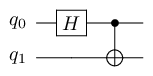

In [3]:
bell_pair_1().display()

Now simulate the circuit. With `nbshots=0`, the simulator displays the ideal statevector: amplitudes as well as probabilities.


In [ ]:
# Display results of the circuit execution on the default QPU
display_result(bell_pair_1())

Etat |00>: probabilité 0.4999999999999999, amplitude (0.7071067811865475+0j)
Etat |11>: probabilité 0.4999999999999999, amplitude (0.7071067811865475+0j)


The output should contain $|00\rangle$ and $|11\rangle$, each with probability $1/2$ and amplitude $1/\sqrt2$.

### Exercise 1.1 – Prepare $|\Psi^+\rangle$

Complete the routine below to prepare

$$|\Psi^+\rangle=\frac{|01\rangle+|10\rangle}{\sqrt2}.$$

*Hint: start from the circuit for $|\Phi^+\rangle$ and think about how to flip one qubit.*


In [ ]:
def bell_pair_2() :
    # Create a quantum routine
    rout = QRoutine()
    # Create 2 qubits in the routine
    qubits = rout.new_wires(2)

    return rout

Check the output. You should obtain $|01\rangle$ and $|10\rangle$, each with probability $1/2$ and positive amplitude $1/\sqrt2$.


In [ ]:
# Display results
display_result(bell_pair_2())

Etat |00>: probabilité 1.0, amplitude (1+0j)


### Exercise 1.2 – Prepare $|\Phi^-\rangle$

Implement the circuit for

$$|\Phi^-\rangle=\frac{|00\rangle-|11\rangle}{\sqrt2}.$$

The two computational-basis probabilities are the same as for $|\Phi^+\rangle$. What changes in the statevector?


In [ ]:
def bell_pair_3() :
    # Create a quantum routine
    rout = QRoutine()
    # Create 2 qubits in the routine
    qubits = rout.new_wires(2)


    return rout

Check both the probabilities and the signs of the amplitudes. The minus sign is a relative phase, not a negative probability.


In [ ]:
# Display results
display_result(bell_pair_3())

Etat |00>: probabilité 1.0, amplitude (1+0j)


### Exercise 1.3 – Prepare $|\Psi^-\rangle$

Implement the circuit for

$$|\Psi^-\rangle=\frac{|01\rangle-|10\rangle}{\sqrt2}.$$

You can reuse the operations from the previous exercises.


In [ ]:
def bell_pair_4() :
    # Create a quantum routine
    rout = QRoutine()
    # Create 2 qubits in the routine
    qubits = rout.new_wires(2)


    return rout

Check that the two nonzero amplitudes have opposite signs.


In [331]:
display_result(bell_pair_4())

Etat |00>: probabilité 1.0, amplitude (1+0j)


### Exercise 1.4 – From ideal probabilities to finite-shot measurements

So far, we have inspected the ideal statevector. Now we will simulate repeated measurements. Consider the Bell state $|\Phi^+\rangle$.

1. Run `bell_pair_1()` with 100 shots, then 1,000 shots, then 10,000 shots.
2. Record the frequencies of outcomes $00$ and $11$.
3. Compare them with the ideal probabilities $P(00)=P(11)=1/2$.
4. Explain why the frequencies are not necessarily exactly equal to $1/2$, and what changes when the number of shots increases.

**Prediction:** before running the simulations, write down which outcomes you expect to observe and which outcomes should never occur in the ideal circuit.

(Write your answers in a markdown cell below)

In [ ]:
# Try several shot counts.
display_result(bell_pair_1(), nbshots=100)
# display_result(bell_pair_1(), nbshots=1000)
# display_result(bell_pair_1(), nbshots=10000)


### Exercise 1.5 – Measuring only one qubit

Use `idx=[0]` to sample only the first qubit of the Bell pair, then use `idx=[1]` to sample only the second.

1. What probabilities do you obtain for 0 and 1 on each qubit?
2. Compare these results with the joint measurement of both qubits.
3. Are the individual outcomes random? Are the two outcomes correlated?

Remember: observing one qubit does not allow us to choose or control the outcome obtained on the other qubit.


(Write your answers in a markdown cell below)

In [ ]:
# Measure the first qubit only, then the second qubit only.
display_result(bell_pair_1(), nbshots=1000, idx=[0])
# Your experiment here


### Exercise 1.6 – The importance of the measurement basis

The states $|\Phi^+\rangle$ and $|\Phi^-\rangle$ have identical computational-basis measurement probabilities. The same is true for $|\Psi^+\rangle$ and $|\Psi^-\rangle$ (We recall that by computational-basis measurement, we mean measuring the Pauli $Z$ on qubits). 

Can we distinguish the states by changing the measurement basis?

Recall that applying H immediately before a computational-basis measurement is equivalent to measuring in the X basis, because $H$ exchanges the X and Z measurement bases.

Complete the routine below to apply H to **both** qubits of a given bell pair routine before sampling them. Note that the measurement itself is performed by `display_result` when finite shots are requested; the H gates change the basis before that measurement.


In [ ]:
def bell_measure_in_x_basis(bell_routine):
    rout = QRoutine()
    qubits = rout.new_wires(2)

    # bell_routine is a QRoutine returned by bell_pair_1(), bell_pair_2(), ...
    bell_routine(qubits)

    # Rotate both qubits so that a computational-basis measurement
    # corresponds to an X-basis measurement.
    # YOUR CODE HERE

    return rout


1. Use this `bell_measure_in_x_basis` routing on both `bell_pair_1()` and `bell_pair_3()` (your $|\Phi^+\rangle$ and $|\Phi^-\rangle$ routines).
2. Compare the outcomes. What happened? Can you distinguish the relative phase now ?
4. Repeat the same idea for $|\Psi^+\rangle$ and $|\Psi^-\rangle$.

(Write your answers in a markdown cell below)

In [ ]:
# Your experiment here

### Exercise 1.7 – Correlations and Pauli observables

For a two-qubit state, we can study correlations by measuring the same Pauli observable on both qubits. For outcomes encoded as $+1$ (measurement result 0) and $-1$ (measurement result 1), the product of the two outcomes is:

- $+1$ when the two bits are equal (`00` or `11`),
- $-1$ when the two bits are different (`01` or `10`).

For $|\Phi^+\rangle$, predict the correlations

$$\langle X\otimes X\rangle,\qquad
\langle Y\otimes Y\rangle,\qquad
\langle Z\otimes Z\rangle.$$




**Write your prediction here**

To measure X on both qubits, apply H to both before computational-basis sampling. To measure Y, apply $R_Z(-\pi/2)$ followed by H to each qubit. For Z, no basis rotation is needed.

Use the measurement frequencies to estimate the correlations. For example,

$$\langle Z\otimes Z\rangle\approx P(00)+P(11)-P(01)-P(10).$$

Do the same for the X and Y bases. Repeat for at least one other Bell state and compare with your predictions.

In [ ]:
# Your experiment here

### A useful summary: expectation values

An observable is a Hermitian operator associated with a measurable physical quantity. Its expectation value in a state $|\psi\rangle$ is

$$\langle O\rangle=\langle\psi|O|\psi\rangle.$$

For a Pauli measurement, the possible outcomes are $+1$ and $-1$. If their estimated frequencies are $P_+$ and $P_-$, then

$$\langle X\rangle\approx P_+-P_-.$$

For two-qubit Pauli correlations, the measured value is the average of the product of the two outcomes. This is why we can estimate correlations from the joint measurement frequencies.

The simulator does not need to return an expectation value directly: we can estimate it from repeated measurement outcomes.


## Part 2: Quantum teleportation

Quantum teleportation transfers an **unknown quantum state** from one qubit to another, using a shared entangled pair and two classical bits. It does not transmit information faster than light, and it does not create a copy of the original state.

Suppose Alice holds a qubit in the state

$$|\psi\rangle_A=\alpha|0\rangle_A+\beta|1\rangle_A,$$

where $\alpha$ and $\beta$ may in general be complex and $|\alpha|^2+|\beta|^2=1$. Alice and Bob have previously shared a Bell pair

$$|\Phi^+\rangle_{ab}=\frac{|00\rangle_{ab}+|11\rangle_{ab}}{\sqrt2},$$

with Alice holding qubit $a$ and Bob holding qubit $b$. The initial three-qubit state (ordered as $A,a,b$) is

$$|\psi\rangle_A\otimes|\Phi^+\rangle_{ab}.
$$

Alice cannot generally determine the amplitudes of an arbitrary unknown state from a single copy and send them classically. Teleportation instead uses entanglement, a joint measurement by Alice, and two classical bits sent to Bob. The original state is not left intact at Alice's end.


### Exercise 2.1 – Preparing a single-qubit state

Start with **real** $\alpha$ and $\beta$, with $\alpha^2+\beta^2=1$. The rotation

$$R_Y(\theta)|0\rangle=\cos(\theta / 2)|0\rangle+\sin(\theta / 2)|1\rangle.$$

What value of $\theta$ prepares $\alpha|0\rangle+\beta|1\rangle$? Complete the below state preparation routine. Be careful to choose the correct quadrant when $\alpha$ or $\beta$ is negative.


In [ ]:
def state_prep(alpha, beta):
    # Create a quantum routine
    rout = QRoutine()
    qubits = rout.new_wires(1)

    alpha = float(np.real(alpha))
    beta = float(np.real(beta))
    if not np.isclose(alpha**2 + beta**2, 1.0):
        raise ValueError("The input amplitudes must be real and normalized.")

    # YOUR CODE HERE

    return rout

Test your routine with a few normalized pairs $(\alpha,\beta)$, including a negative coefficient. The amplitudes should match the requested state. For example, use $\alpha=\sqrt3/2$ and $\beta=-1/2$.


In [ ]:
alpha = np.sqrt(3.) / 2.
beta = -0.5

display_result(state_prep(alpha, beta))


### Exercise 2.2 – Preparing the initial three-qubit state

Write a routine that prepares

$$|\psi\rangle_A\otimes|\Phi^+\rangle_{ab}.
$$

Use `state_prep` for qubit A and `bell_pair_1` for qubits $a,b$. Keep the qubit order $(A,a,b)$ throughout the rest of the exercise.


In [ ]:
def initialisation(alpha, beta):
    rout = QRoutine()
    qubit_A = rout.new_wires(1)
    qubits_ab = rout.new_wires(2)

    # YOUR CODE HERE

    return rout


Check the statevector. The only basis states with nonzero amplitudes should be $|000\rangle$, $|011\rangle$, $|100\rangle$, and $|111\rangle$. Their amplitudes depend on $\alpha$ and $\beta$.


In [ ]:
display_result(initialisation(alpha, beta))


### The Bell measurement and Bob's correction

Alice now applies CNOT from $A$ to $a$, followed by H on $A$. The resulting state can be grouped according to Alice's two computational-basis outcomes:

$$\begin{aligned}
|\Psi\rangle=\frac12[&|00\rangle_{Aa}(\alpha|0\rangle+\beta|1\rangle)_b\\
+&|01\rangle_{Aa}(\beta|0\rangle+\alpha|1\rangle)_b\\
+&|10\rangle_{Aa}(\alpha|0\rangle-\beta|1\rangle)_b\\
+&|11\rangle_{Aa}(\beta|0\rangle-\alpha|1\rangle)_b].
\end{aligned}$$

Alice measures $A$ and $a$. Depending on the two classical outcomes, Bob applies a correction to qubit $b$:

| Alice's result $(A,a)$ | Bob's correction |
|---|---|
| 00 | $I$ (no gate) |
| 01 | $X$ |
| 10 | $Z$ |
| 11 | $ZX$ (apply X and Z; their order differs only by a global phase) |

Equivalently, apply Z conditioned on the measurement of A and X conditioned on the measurement of a.


### Exercise 2.3 – Alice's intermediate operations

Implement the CNOT and H gates described above. The qubit order is still $(A,a,b)$.


In [ ]:
def intermediate_operation():
    rout = QRoutine()
    qubit_A = rout.new_wires(1)
    qubits_ab = rout.new_wires(2)

    # Alice's operations: CNOT(A, a), then H(A)

    return rout


### Exercise 2.4 – Classically controlled corrections

Complete the teleportation program below. It must:

1. Allocate three qubits and two classical bits.
2. Prepare the initial state and apply Alice's intermediate operations.
3. Measure qubits A and a into the two classical bits.
4. Apply Z to Bob's qubit if the result for A is 1.
5. Apply X to Bob's qubit if the result for a is 1.

The measurement results are classical information; the corrections are therefore classically controlled gates.


In [ ]:
def teleportation(alpha, beta):
    prog = Program()
    qubits = prog.qalloc(3)
    bits = prog.calloc(2)

    initialisation(alpha, beta)(qubits)
    intermediate_operation()(qubits)

    # Alice measures A and a
    prog.measure(qubits[0:2], bits)

    # Conditional corrections on Bob's qubit
    prog.cc_apply(bits[0], Z, qubits[2])
    # Add the X correction conditioned on bits[1]

    return prog


Inspect the circuit generated by your program. Make sure that the two measurements occur before the classically controlled corrections.


In [ ]:
circuit = teleportation(alpha, beta).to_circ()
circuit.display()


### Exercise 2.5 – First check: computational-basis probabilities

Run the teleportation circuit with a finite number of shots and observe Bob's qubit (qubit 2). Compare the probabilities of 0 and 1 with those of the original state.

This is a useful first check, but it is **not a complete verification**: two different states can have identical computational-basis probabilities. For example, $|+\rangle$ and $| - \rangle$ both give 50% probability for 0 and 50% for 1.


In [ ]:
display_result(circuit, nbshots=2000, idx=[2])


### Exercise 2.6 – Verify teleportation in the X basis

To measure X, apply H to Bob's qubit after the teleportation corrections and before the final sampling. A computational-basis measurement after this H gate is an X-basis measurement.

1. Teleport $|+\rangle=(|0\rangle+|1\rangle)/\sqrt2$. What outcome should be obtained in the X basis?
2. Repeat for $|-\rangle=(|0\rangle-|1\rangle)/\sqrt2$.
3. Compare the observed frequencies with the theoretical predictions.

Modify the circuit or create a small helper routine that adds the final H gate to Bob's qubit. Do not apply this H before Alice's measurements or before the conditional corrections.

(Write your code and anwsers in a markdown below)


In [ ]:
# Example starting point: prepare |+> by setting alpha=beta=1/sqrt(2).
alpha_x = 1. / np.sqrt(2.)
beta_x = 1. / np.sqrt(2.)

# Write a teleportation circuit for the X-basis verification, that add H on qubit 2 AFTER the teleportation protocol, then sample qubit 2.


# Complete the X-basis verification here.



### What have we verified?

For a single-qubit pure state, the three Pauli expectation values $\langle X\rangle$, $\langle Y\rangle$ and $\langle Z\rangle$ determine its Bloch vector. Testing teleportation in the X, Y and Z bases therefore checks much more than computational-basis probabilities alone.

In an experiment, finite sampling means that the measured frequencies will only agree with the theoretical values within statistical fluctuations. Increasing the number of shots improves the precision of the estimates.


## Part 3: Expectation values and observables

In physics, we are often interested not only in the complete state but in measurable quantities. A Hermitian operator $O$ represents an **observable**. For a state $|\psi\rangle$, its expectation value is

$$\langle O\rangle=\langle\psi|O|\psi\rangle.$$

For a Pauli observable ($X$, $Y$ or $Z$), a measurement gives the eigenvalue $+1$ or $-1$. In a finite-shot simulation, we estimate the expectation value by averaging these outcomes. If $N_+$ outcomes are $+1$ and $N_-$ outcomes are $-1$,

$$\langle O\rangle\approx\frac{N_+-N_-}{N_++N_-}=P_+-P_-.$$

To measure X or Y using the computational-basis sampler, rotate the measurement basis first:

- **Z measurement:** no rotation;
- **X measurement:** apply H;
- **Y measurement:** apply $R_Z(-\pi/2)$, then H.



### Exercise 3.1 – Measuring the three Pauli observables

Prepare each of the following states and estimate $\langle X\rangle$, $\langle Y\rangle$ and $\langle Z\rangle$ using finite-shot simulations:

- $|0\rangle$;
- $|1\rangle$;
- $|+\rangle=(|0\rangle+|1\rangle)/\sqrt2$;
- $|+i\rangle=(|0\rangle+i|1\rangle)/\sqrt2$.

For each observable, convert the desired measurement into a computational-basis measurement using the rotations described above. Record your estimates and compare them with the theoretical values. Use enough shots to make the statistical fluctuations reasonably small.


In [ ]:

# Write a function to measure a single qubit in the X, Y or Z basis.
def single_qubit_measurement(state_routine, basis="Z"):
    rout = QRoutine()
    qubit = rout.new_wires(1)

    # YOUT CODE HERE

    return rout

# Example: prepare |+> and measure it in the X basis.
# display_result(single_qubit_measurement(state_prep(1/np.sqrt(2), 1/np.sqrt(2)), "X"), nbshots=2000)

# For |+i> you might need to write a state preparation function for this, since it has complex coefficients (or simply update the state_prep function to handle complex coefficients).

### Exercise 3.2 – Reconstructing a Bloch vector

A single-qubit state can be represented by its Bloch vector

$$\vec r=(\langle X\rangle,\langle Y\rangle,\langle Z\rangle).$$

Use the measurement function from the previous exercise to write a function that reconstructs the Bloch vector of a given prepared state.
(Hint: you can reuse parts of the `display_result`function to understand how to run the circuits and exploit their results)


1. What are the expected Bloch vectors for the four states?
2. What is the norm of each reconstructed vector?
3. Why might the norm estimated from a finite number of shots differ slightly from its ideal value?
4. What does the Bloch vector tell you about the state that a single computational-basis measurement distribution does not?

For a pure single-qubit state, the ideal Bloch vector has unit norm.

(write your answers in a markdown cell below)

In [ ]:
# Reconstruct Bloch Sphere from several shots 
def reconstruct_bloch_vector(state_routine, nbshots=1000):
    if nbshots <= 0:
        raise ValueError("nbshots must be a positive integer.")
    
    # Compute res_x, the result of the X basis measurement of state_routine
    # YOUR CODE HERE
    expval_x = (sum(sample.probability * (1 if str(sample.state) == '|0>' else -1) for sample in res_x))

    # SAME FOR Y
    expval_y = (sum(sample.probability * (1 if str(sample.state) == '|0>' else -1) for sample in res_y))

    # SAME FOR Z
    expval_z = (sum(sample.probability * (1 if str(sample.state) == '|0>' else -1) for sample in res_z))

    return [expval_x, expval_y, expval_z]



### Exercise 3.3 – Revisiting Bell correlations

Return to the Bell pair $|\Phi^+\rangle$. From Part 1, you estimated the two-qubit correlations $\langle X\otimes X\rangle$, $\langle Y\otimes Y\rangle$ and $\langle Z\otimes Z\rangle$.

Explain why these are expectation values of two-qubit observables, and compare their values with the single-qubit expectation values of either qubit taken separately. What does this tell you about the difference between local properties and correlations in an entangled state?

(Write your answers in a markdown cell below)

## To learn more

- **Entanglement and Bell inequalities.** Entanglement means that the joint state cannot be described as a product of independent states for the two qubits. Alain Aspect's experiments tested Bell inequalities and confirmed predictions of quantum mechanics: https://en.wikipedia.org/wiki/Aspect%27s_experiment
- **No faster-than-light communication.** Teleportation requires Alice to send Bob two classical bits. Bob cannot recover the state before receiving this classical information, so teleportation does not allow superluminal communication.
- **No-cloning theorem.** An arbitrary unknown quantum state cannot be copied perfectly. Teleportation does not violate this theorem: Alice's measurement consumes the original input state, and Bob reconstructs the state on his qubit after receiving the classical information. It is a transfer, not a cloning operation: https://en.wikipedia.org/wiki/No-cloning_theorem

